# Lab 4: Colour Classification of the Indian Flag with LDA

MLPR, Semester 4. Points are picked on the saffron, white and green strips of the flag, converted from RGB to the CIELAB colour space, and separated with Linear Discriminant Analysis using the a* and b* channels.

The lab asks for points to be clicked by hand (`select_points` below). To make the notebook reproducible, it loads the 60 points I selected (20 per strip) from `data/flag_points.csv`. Set `INTERACTIVE = True` to click new points in a desktop window.

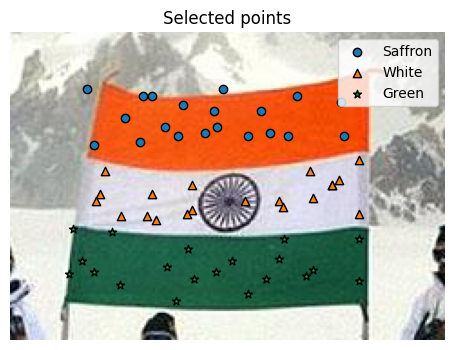

In [1]:
import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

INTERACTIVE = False
Number_of_points = 20
img = cv2.imread("data/Indian_Flag.jpg")
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def select_points(img, title):
    # Click Number_of_points points on the image; returns [row, col, rgb] for each
    fig, ax = plt.subplots()
    ax.imshow(img_rgb)
    ax.set_title(title)
    plt.show(block=False)
    points = []
    while len(points) < Number_of_points:
        xy = plt.ginput(1, timeout=0)
        if xy:
            col, row = map(int, xy[0])
            points.append([row, col, img_rgb[row, col]])
            plt.scatter(col, row, c="black", s=10)
            plt.draw()
    plt.close()
    return points


if INTERACTIVE:
    matplotlib.use("TkAgg")
    pts = {s: select_points(img, f"{s} strip") for s in ["Saffron", "White", "Green"]}
else:
    saved = pd.read_csv("data/flag_points.csv")
    pts = {s: [[r, c, img_rgb[r, c]] for r, c in g[["row", "col"]].values] for s, g in saved.groupby("strip", sort=False)}

fig, ax = plt.subplots(figsize=(8, 4))
ax.imshow(img_rgb[230:400, 480:720])
for s, mk in zip(pts, ["o", "^", "*"]):
    ax.scatter([p[1] - 480 for p in pts[s]], [p[0] - 230 for p in pts[s]], marker=mk, edgecolor="k", label=s)
ax.legend(); ax.axis("off"); ax.set_title("Selected points")
plt.show()

Training accuracy of LDA on the selected points: 96.67%


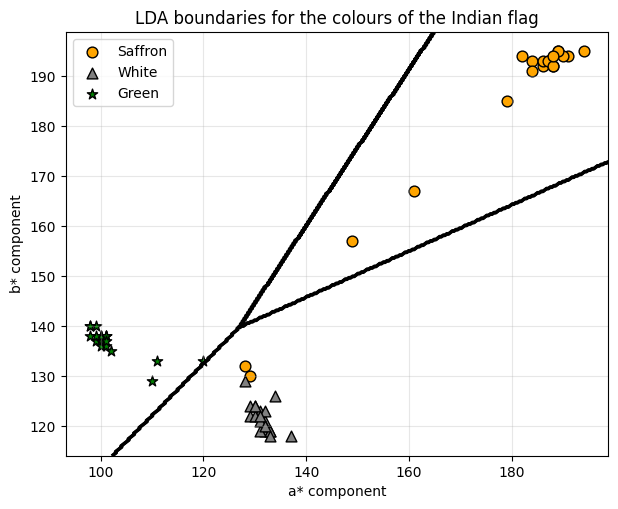

In [2]:
def rgb_to_lab(rgb):
    return cv2.cvtColor(np.uint8([[rgb]]), cv2.COLOR_RGB2Lab)[0][0]

lab = {s: np.array([rgb_to_lab(rgb) for _, _, rgb in pts[s]]) for s in pts}
X = np.vstack([lab[s][:, 1:3] for s in ["Saffron", "White", "Green"]]).astype(float)   # a*, b*
y = np.repeat([0, 1, 2], Number_of_points)

lda = LinearDiscriminantAnalysis().fit(X, y)
print(f"Training accuracy of LDA on the selected points: {lda.score(X, y):.2%}")

plt.figure(figsize=(7, 5.5))
for k, (s, c, mk) in enumerate(zip(["Saffron", "White", "Green"], ["orange", "grey", "green"], ["o", "^", "*"])):
    plt.scatter(X[y == k, 0], X[y == k, 1], c=c, marker=mk, s=60, edgecolor="k", label=s)
xlim, ylim = plt.xlim(), plt.ylim()
xx, yy = np.meshgrid(np.linspace(*xlim, 300), np.linspace(*ylim, 300))
Z = lda.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
plt.contour(xx, yy, Z, colors="k", linewidths=2)
plt.xlabel("a* component"); plt.ylabel("b* component")
plt.title("LDA boundaries for the colours of the Indian flag")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig("images/lab04_lda.png")
plt.show()

In Lab colour space the three strips separate cleanly. Saffron has high a* (red) and high b* (yellow), green has negative a*, and white sits near the neutral point. LDA's straight-line boundaries classify 58 of the 60 selected points correctly (96.7%). The two errors are points clicked near the edge between strips, where the colours blend.

## Report

1. **Assumptions of LDA:** each class follows a Gaussian distribution, and all classes share the same covariance matrix. If these are badly violated (very different spreads or non-Gaussian classes), the linear boundaries become sub-optimal.
2. **Hyperparameters:** `solver` (`svd`, `lsqr`, `eigen`) chooses the algorithm. `shrinkage` regularises the covariance estimate, which helps with few samples or many features.
3. **Assessing the model:** a confusion matrix and classification accuracy, ideally on held-out points, show how well the classes are separated.
4. **Limitations:** LDA assumes equal covariances and Gaussian classes, fails when classes overlap heavily, and is sensitive to outliers. These can be addressed with data cleaning, feature engineering, or by switching to QDA when covariances differ.
5. **Applications:** colour-based classification (flags, product sorting, quality inspection), face recognition (Fisherfaces) and document or email classification.